# **Preparación de datos — Modelo IA de Segmentación de Clientes (K-means RFM) v2**

La segmentación agrupa a los clientes según su **valor** para el negocio, usando el enfoque **RFM**:
- **R**ecencia: hace cuánto compró por última vez.
- **F**recuencia: cuántas veces compró en el último año.
- **M**onetario: cuánto gasta frente al cliente típico de **su** tienda.

Segmentos del CRM (tabla `segmentos`): **1 Bajo valor · 2 Medio valor · 3 Alto valor · 4 Nuevos** (sin compras).

**Cambios frente a la segmentación anterior (`app/ia/segments`)**
| Antes | Ahora |
|---|---|
| El K-means entrenado **no se usaba**: la app asignaba segmentos con reglas de percentiles de CLV | La app usa el K-means entrenado |
| Clientes "en riesgo" filtrados **antes** de agrupar: mezclaba valor y riesgo | Se agrupa por **valor**; el riesgo lo da el modelo de abandono, por separado |
| 86 clientes de entrenamiento; 3 variables sin transformar | Miles de clientes reales (Online Retail II); variables con `log` y estandarizadas |
| Etiqueta de clúster 0 confundida con "bajo valor" (error) | Cada clúster se nombra según su **centroide** |
| `probabilidad_churn` inventada por fórmula como variable | Solo variables RFM medidas |
| Sin métricas de calidad | Silhouette, Davies-Bouldin, Calinski-Harabasz, estabilidad y **utilidad de negocio** (ingreso futuro por segmento) |

**Pasos del notebook**
1. Configuración y carga de Online Retail II
2. Limpieza
3. Análisis de las variables RFM → justificación de la transformación logarítmica
4. Cortes temporales: variables (pasado) + resultados de negocio a 90 días (futuro, solo para evaluar)
5. Verificación de ausencia de fuga de datos
6. Dataset de validación externa (CDNOW)
7. Auditoría de la segmentación anterior
8. Exportación a la carpeta `Data/`

## **1. Configuración y carga de datos**
Se usan los mismos datasets y **la misma función de variables** (`../churn_v2/features.py`) que el modelo de abandono. Así ambos modelos ven al cliente igual, en el notebook y en la API.

In [1]:
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(0, "../churn_v2")          # features.py compartido con el modelo de abandono
from features import construir_features, construir_snapshot

DATASETS = Path("../datasets")
SALIDA = Path("Data"); SALIDA.mkdir(exist_ok=True)

VENTANA_OBSERVACION = 365      # días de historia para calcular R, F y M
VENTANA_FUTURA = 90            # días posteriores al corte para medir el valor real de cada segmento
RFM = ["recencia_dias", "frecuencia", "log_monetario_relativo"]

orii = pd.read_csv(DATASETS / "online_retail_ii.csv.gz", dtype={"Invoice": str, "StockCode": str},
                   parse_dates=["InvoiceDate"])
print("Filas:", len(orii), "|", orii["InvoiceDate"].min().date(), "->", orii["InvoiceDate"].max().date())

Filas: 1067371 | 2009-12-01 -> 2011-12-09


## **2. Limpieza**
Igual que en el modelo de abandono:
- Sin cliente nulo.
- Sin cancelaciones (facturas "C").
- Cantidad y precio mayores que 0.
- Solo Reino Unido.

Contrato de transacciones: `cliente_id, factura_id, fecha, monto, tienda_id`.

In [2]:
df = orii.dropna(subset=["CustomerID"])
df = df[~df["Invoice"].str.startswith("C") & (df["Quantity"] > 0) & (df["Price"] > 0) & (df["Country"] == "United Kingdom")]
trans = pd.DataFrame({"cliente_id": df["CustomerID"].astype(int).astype(str), "factura_id": df["Invoice"].astype(str),
                      "fecha": df["InvoiceDate"], "monto": df["Quantity"] * df["Price"],
                      "tienda_id": "online_retail_ii"}).sort_values("fecha").reset_index(drop=True)
print(f"Líneas: {len(trans)} | Clientes: {trans.cliente_id.nunique()} | Facturas: {trans.factura_id.nunique()}")

Líneas: 725250 | Clientes: 5350 | Facturas: 33541


## **3. Variables RFM**
| Variable | Cálculo |
|---|---|
| `recencia_dias` | Días desde la última compra |
| `frecuencia` | Nº de compras en los últimos 365 días |
| `log_monetario_relativo` | log(gasto anual del cliente / gasto anual del cliente **mediano de su tienda**) |

El monetario es **relativo a la tienda**: "alto valor" significa alto para *ese* negocio, sea una tienda de barrio en Santander de Quilichao o un mayorista. Además, no depende de la moneda.

Veamos la forma de las distribuciones en un corte (1 de junio de 2011):

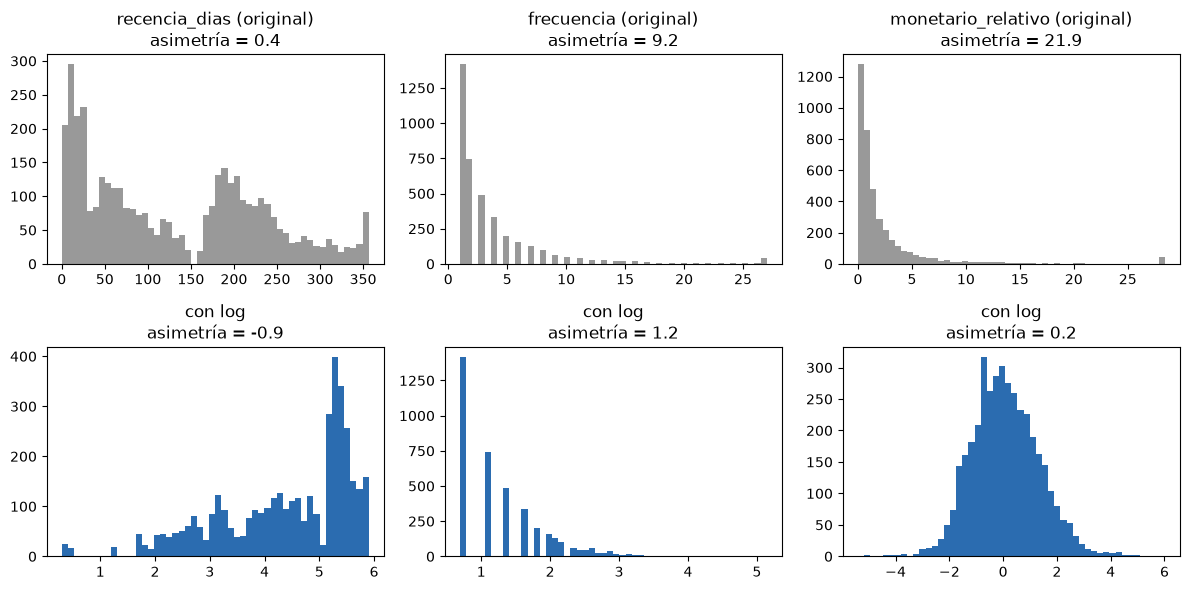

Correlaciones (con log):


,log_recencia,log_frecuencia,log_monetario_rel
log_recencia,1.00,-0.57,-0.48
log_frecuencia,-0.57,1.00,0.82
log_monetario_rel,-0.48,0.82,1.00


In [3]:
ej = construir_features(trans, "2011-06-01", VENTANA_OBSERVACION)
fig, ejes = plt.subplots(2, 3, figsize=(12, 6))
for j, col in enumerate(RFM):
    crudo = np.exp(ej[col]) if col.startswith("log_") else ej[col]
    transf = ej[col] if col.startswith("log_") else np.log1p(ej[col])
    ejes[0, j].hist(crudo.clip(upper=crudo.quantile(0.99)), bins=50, color="#999")
    ejes[0, j].set_title(f"{col.replace('log_', '')} (original)\nasimetría = {pd.Series(crudo).skew():.1f}")
    ejes[1, j].hist(transf, bins=50, color="#2b6cb0")
    ejes[1, j].set_title(f"con log\nasimetría = {pd.Series(transf).skew():.1f}")
plt.tight_layout(); plt.show()
print("Correlaciones (con log):")
pd.DataFrame({"log_recencia": np.log1p(ej.recencia_dias), "log_frecuencia": np.log1p(ej.frecuencia),
              "log_monetario_rel": ej.log_monetario_relativo}).corr().round(2)

**Interpretación:** las tres variables están muy sesgadas: pocos clientes compran muchísimo. K-means usa distancias, así que sin transformar, unos pocos clientes extremos definirían los grupos. Con `log` las distribuciones quedan mucho más simétricas, y después se **estandarizan** para que R, F y M pesen lo mismo. Frecuencia y monetario están correlacionados, como es habitual en RFM, pero no son idénticos.

## **4. Cortes temporales y resultados de negocio**
Se usan los mismos cortes que en el modelo de abandono:
- **Entrenamiento:** dic-2010 a mar-2011.
- **Validación:** jun-2011.
- **Test:** sep-2011.

En cada corte:
- **Variables RFM** → solo con compras **anteriores** al corte (lo que el CRM conoce).
- **Resultado de negocio** en los 90 días siguientes → si el cliente volvió a comprar y cuánto gastó. **No se usa para agrupar.** Sirve para comprobar que los segmentos "alto valor" realmente aportan más ingresos en el futuro.

In [5]:
CORTES = {"train": ["2010-12-01", "2011-01-01", "2011-02-01", "2011-03-01"],
          "valid": ["2011-06-01"], "test": ["2011-09-01"]}

def resultado_futuro(trans, corte, dias):
    corte = pd.Timestamp(corte)
    f = trans[(trans.fecha >= corte) & (trans.fecha < corte + pd.Timedelta(days=dias))]
    g = f.groupby("cliente_id")
    return pd.DataFrame({"gasto_futuro": g["monto"].sum(), "compras_futuras": g["factura_id"].nunique()})

partes = []
for conjunto, lista in CORTES.items():
    for corte in lista:
        s = construir_snapshot(trans, corte, VENTANA_FUTURA, VENTANA_OBSERVACION)
        fut = resultado_futuro(trans, corte, VENTANA_FUTURA)
        s = s.merge(fut, left_on="cliente_id", right_index=True, how="left").fillna({"gasto_futuro": 0, "compras_futuras": 0})
        s["volvio_a_comprar"] = 1 - s.pop("churn")
        s["conjunto"] = conjunto
        partes.append(s)
datos = pd.concat(partes, ignore_index=True)

datos.groupby("conjunto").agg(filas=("cliente_id", "size"), clientes=("cliente_id", "nunique"),
                              volvio=("volvio_a_comprar", "mean"), gasto_futuro_medio=("gasto_futuro", "mean")
                              ).loc[["train", "valid", "test"]].round(3)

,filas,clientes,volvio,gasto_futuro_medio
conjunto,,,,
train,15631,4164,0.339,310.839
valid,3969,3969,0.361,332.431
test,3947,3947,0.492,564.039


## **5. Verificación de ausencia de fuga de datos**
- Las variables RFM usan solo compras **anteriores** al corte.
- El resultado de negocio usa solo compras **posteriores** al corte.
- Las variables de un corte **no cambian** si se agregan compras futuras.

In [6]:
for corte, g in datos.groupby("fecha_corte"):
    assert (g["recencia_dias"] > 0).all(), f"recencia <= 0 en {corte}"
    assert (g["antiguedad_dias"] <= VENTANA_OBSERVACION + 1).all()
    fut = resultado_futuro(trans, corte, VENTANA_FUTURA)
    esperado = g["cliente_id"].map(fut["gasto_futuro"]).fillna(0)
    assert np.allclose(esperado.values, g["gasto_futuro"].values), "gasto futuro inconsistente"
c = pd.Timestamp(CORTES["valid"][0])
assert construir_features(trans[trans.fecha < c], c).equals(construir_features(trans, c)), "las variables dependen del futuro"
print("✔ Sin fuga de datos en", datos["fecha_corte"].nunique(), "cortes")

✔ Sin fuga de datos en 6 cortes


## **6. Validación externa: CDNOW**
Tienda de discos de EE. UU. (1997–1998): otro negocio, otra moneda y otra época. Se usa el corte del 1 de abril de 1998.

In [7]:
cd = pd.read_csv(DATASETS / "CDNOW_master.txt", sep=r"\s+", header=None, names=["id", "fecha", "cds", "valor"],
                 dtype={"id": str, "fecha": str})
cd = cd[cd["valor"] > 0]
trans_cd = pd.DataFrame({"cliente_id": cd["id"], "factura_id": cd["id"] + "_" + cd["fecha"],
                         "fecha": pd.to_datetime(cd["fecha"], format="%Y%m%d"), "monto": cd["valor"], "tienda_id": "cdnow"})
cd_test = construir_snapshot(trans_cd, "1998-04-01", VENTANA_FUTURA, VENTANA_OBSERVACION)
cd_test = cd_test.merge(resultado_futuro(trans_cd, "1998-04-01", VENTANA_FUTURA), left_on="cliente_id",
                        right_index=True, how="left").fillna({"gasto_futuro": 0, "compras_futuras": 0})
cd_test["volvio_a_comprar"] = 1 - cd_test.pop("churn")
print(f"CDNOW 1998-04-01: {len(cd_test)} clientes, volvieron a comprar {cd_test.volvio_a_comprar.mean():.1%}")

CDNOW 1998-04-01: 9526 clientes, volvieron a comprar 29.8%


## **7. Auditoría de la segmentación anterior**
Se revisa el modelo guardado en `app/ia/segments/Data`, si todavía existe.

In [8]:
auditoria = {
    "modelo_kmeans_usado_por_la_app": False,
    "segmentacion_en_produccion": "reglas: churn>=0.65 o >90 días sin comprar -> bajo valor; resto por percentiles de CLV 33/45/22",
    "clientes_entrenamiento_kmeans": 86,
    "variables": ["total_compras", "frecuencia_compra", "dias_ultima_compra"],
    "error_etiquetas": "el clúster 0 de K-means se fusionó con la etiqueta 0 de 'bajo valor' (distribución 530/57/11)",
}
ruta_vieja = Path("../segments/Data")
if (ruta_vieja / "kmeans_model.pkl").exists():
    import joblib
    km_v1, sc_v1 = joblib.load(ruta_vieja / "kmeans_model.pkl"), joblib.load(ruta_vieja / "kmeans_scaler.pkl")
    centros = pd.DataFrame(sc_v1.inverse_transform(km_v1.cluster_centers_), columns=auditoria["variables"]).round(2)
    centros["clientes"] = np.bincount(km_v1.labels_)
    auditoria["centroides_v1"] = centros.to_dict(orient="records")
    display(centros)
    print("El clúster 0 (frecuencia más alta) quedó mezclado con los clientes de 'bajo valor'.")
else:
    print("La carpeta de la segmentación anterior ya no existe; se usan los hallazgos documentados.")
print(json.dumps({k: v for k, v in auditoria.items() if k != "centroides_v1"}, indent=2, ensure_ascii=False))

,total_compras,frecuencia_compra,dias_ultima_compra,clientes
0,7.83,4.98,67.00,18
1,6.42,1.34,40.58,57
2,36.45,1.07,68.55,11


El clúster 0 (frecuencia más alta) quedó mezclado con los clientes de 'bajo valor'.
{
  "modelo_kmeans_usado_por_la_app": false,
  "segmentacion_en_produccion": "reglas: churn>=0.65 o >90 días sin comprar -> bajo valor; resto por percentiles de CLV 33/45/22",
  "clientes_entrenamiento_kmeans": 86,
  "variables": [
    "total_compras",
    "frecuencia_compra",
    "dias_ultima_compra"
  ],
  "error_etiquetas": "el clúster 0 de K-means se fusionó con la etiqueta 0 de 'bajo valor' (distribución 530/57/11)"
}


## **8. Exportar los datos preparados**

In [9]:
datos.to_csv(SALIDA / "seg_conjuntos.csv", index=False)
cd_test.to_csv(SALIDA / "cdnow_seg_test.csv", index=False)
info = {"ventana_observacion_dias": VENTANA_OBSERVACION, "ventana_futura_dias": VENTANA_FUTURA, "variables_rfm": RFM,
        "cortes": CORTES, "auditoria_segmentacion_anterior": auditoria}
(SALIDA / "info_preparacion.json").write_text(json.dumps(info, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
for f in sorted(SALIDA.iterdir()):
    print(f"  {f.name:28s} {f.stat().st_size / 1e6:6.2f} MB")

  cdnow_seg_test.csv             1.52 MB
  info_preparacion.json          0.00 MB
  seg_conjuntos.csv              4.93 MB
